# PS-21 — Kidney Abnormality Detection from CT

**Name:** Vetriprasath V | **Register No.:** RA2311026050176 | **Section:** A | **Date:** 16-11-2026

**Task.** Classify a kidney CT slice as **Normal, Cyst, Stone or Tumour** (4 classes).

**Specific challenge named in the problem statement.**
1. *Data leakage* — many slices come from the same patient study, so a random split can put almost identical slices in both train and test.
2. *Class imbalance* — Stone is the smallest class, so its **recall must be reported separately**.

**Plan of this notebook**

| Step | Part C item | What happens |
|---|---|---|
| 1 | – | Setup, fixed seed, library versions |
| 2 | 5a | Load data, images per class, sample images |
| 3 | challenge | Show that leakage is real; rebuild *pseudo-patient studies* |
| 4 | 5b | Two splits with a fixed seed: **random** (leaky) and **grouped by study** (honest) |
| 5 | 5c, 5d | Transfer-learning CNN, pre-processing, augmentation, learning curves |
| 6 | 5e | One evaluation on the test set: accuracy, per-class P/R/F1, macro-F1, confusion matrix, **Stone recall** |
| 7 | 5f | Misclassified test images + Grad-CAM |
| 8 | innovation | Imbalance ablation (no class weights), lightweight backbone |
| 9 | – | Summary and reproducibility checklist |

**Dataset.** CT Kidney Dataset: Normal-Cyst-Tumor-Stone (Kaggle, Islam et al.), 12,446 images — the full set is used.

## 1. Setup, seed and versions

In [1]:
import os, re, json, time, random, platform, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix)

# ---------------- configuration (everything that affects the numbers) ----------------
SEED      = 42
DATA_DIR  = Path("data/kidney")      # folder that contains Normal/ Cyst/ Stone/ Tumor/  (change on lab system)
CACHE_DIR = Path("cache");   CACHE_DIR.mkdir(exist_ok=True)
OUT_DIR   = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
CLASSES   = ["Normal", "Cyst", "Stone", "Tumor"]
STONE     = CLASSES.index("Stone")
IMG       = 224          # input size expected by ImageNet-pretrained backbones
BATCH     = 64
EPOCHS    = 3            # short training budget (laptop GPU); early stopping kept as a safeguard
PATIENCE  = 3
TRAIN_STRIDE = 8         # train on every 8th slice (file number divisible by 8); see section 5
LR        = 3e-4
WD        = 1e-4

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")

print("python     ", platform.python_version())
print("torch      ", torch.__version__, "| torchvision", torchvision.__version__)
print("numpy      ", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("device     ", device, "|", platform.platform())
print("seed       ", SEED)

python      3.9.6
torch       2.8.0 | torchvision 0.23.0
numpy       2.0.2 | pandas 2.3.3 | sklearn 1.6.1
device      mps | macOS-27.0-arm64-arm-64bit
seed        42


## 2. Load the data (Part C 5a)

Each class is one folder. I read every file name, keep the number inside the brackets (`Stone- (17).jpg` → 17) because it turns out to matter for leakage, and record the original image size.

Total images: 12446


,images,share %
label,,
Normal,5077,40.79
Cyst,3709,29.80
Stone,1377,11.06
Tumor,2283,18.34


Imbalance ratio (largest / smallest) = 3.69


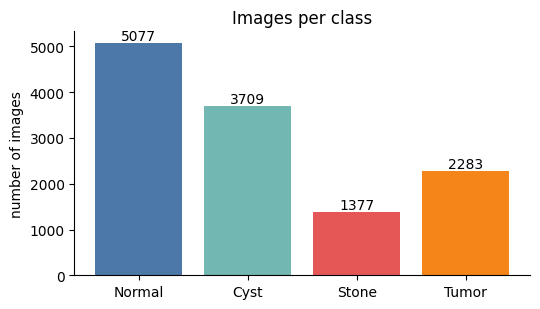

In [2]:
rows = []
for c in CLASSES:
    for p in sorted((DATA_DIR / c).iterdir()):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append({"path": str(p), "label": c, "y": CLASSES.index(c),
                         "num": int(re.search(r"\((\d+)\)", p.name).group(1))})
df = pd.DataFrame(rows)

counts = df["label"].value_counts().reindex(CLASSES)
summary = pd.DataFrame({"images": counts, "share %": (100 * counts / len(df)).round(2)})
print("Total images:", len(df))
display(summary)
print(f"Imbalance ratio (largest / smallest) = {counts.max() / counts.min():.2f}")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(CLASSES, counts.values, color=["#4c78a8", "#72b7b2", "#e45756", "#f58518"])
ax.bar_label(bars); ax.set_ylabel("number of images"); ax.set_title("Images per class")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig_class_counts.png", dpi=200); plt.show()

### Cache the images at 224 × 224

CT slices are grey-scale, so I store **one channel** as `uint8`. The whole dataset then fits in about 625 MB of RAM and training does not have to decode JPEGs again every epoch. Resizing is the only thing done here; normalisation and augmentation happen later, at training time.

In [3]:
cache_x, cache_meta = CACHE_DIR / f"X{IMG}.npy", CACHE_DIR / "sizes.csv"
if cache_x.exists() and cache_meta.exists() and len(pd.read_csv(cache_meta)) == len(df):
    X = np.load(cache_x); sizes = pd.read_csv(cache_meta)
else:
    X = np.zeros((len(df), IMG, IMG), dtype=np.uint8); wh = []
    for i, p in enumerate(df["path"]):
        im = Image.open(p); wh.append(im.size)
        X[i] = np.asarray(im.convert("L").resize((IMG, IMG), Image.BILINEAR))
    sizes = pd.DataFrame(wh, columns=["w", "h"])
    np.save(cache_x, X); sizes.to_csv(cache_meta, index=False)
df["w"], df["h"] = sizes["w"].values, sizes["h"].values
print("cached array:", X.shape, X.dtype, f"{X.nbytes / 1e6:.0f} MB")
print("original sizes:", df.groupby(["w", "h"]).size().sort_values(ascending=False).head(4).to_dict(),
      "...", df[["w", "h"]].drop_duplicates().shape[0], "different sizes in total")

cached array: (12446, 224, 224) uint8 624 MB
original sizes: {(512, 512): 7709, (798, 646): 240, (804, 651): 179, (768, 622): 177} ... 77 different sizes in total


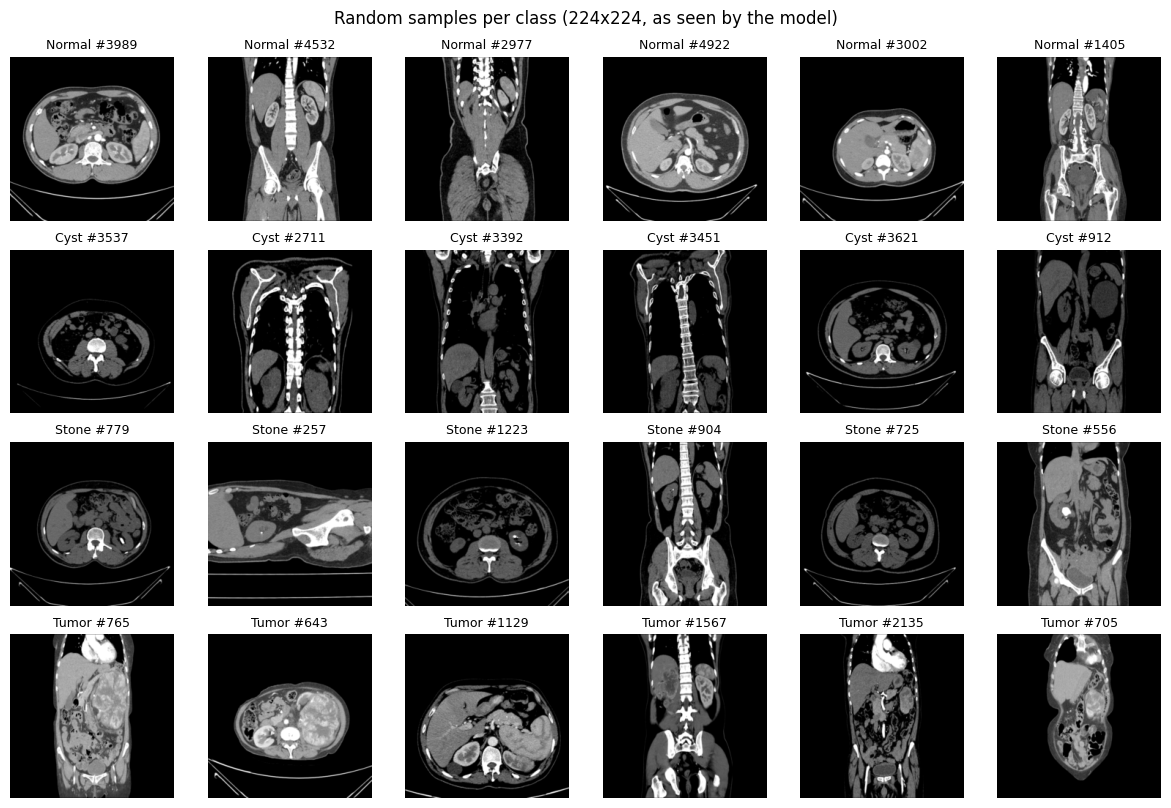

In [4]:
# A few random samples from each class
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 6, figsize=(12, 8.2))
for r, c in enumerate(CLASSES):
    for k, i in enumerate(rng.choice(df.index[df.label == c], 6, replace=False)):
        axes[r, k].imshow(X[i], cmap="gray"); axes[r, k].axis("off")
        axes[r, k].set_title(f"{c} #{df.num[i]}", fontsize=9)
plt.suptitle("Random samples per class (224x224, as seen by the model)")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig_samples.png", dpi=150); plt.show()

## 3. The specific challenge: is leakage real in this dataset?

The dataset gives **no patient ID** — only a class folder and a file number. So before splitting I check two things:

1. Are neighbouring file numbers neighbouring slices of the same scan?
2. If so, how easy is the task for a "model" that only memorises?

To compare images cheaply every slice is shrunk to 32 × 32, mean-centred and length-normalised; the dot product of two such vectors is their **Pearson correlation** (1.0 = identical).

correlation between file k and file k+1 (same class):
count    12442.0000
mean         0.9867
std          0.0916
min         -0.0902
5%           0.9958
25%          0.9982
50%          0.9989
max          1.0000


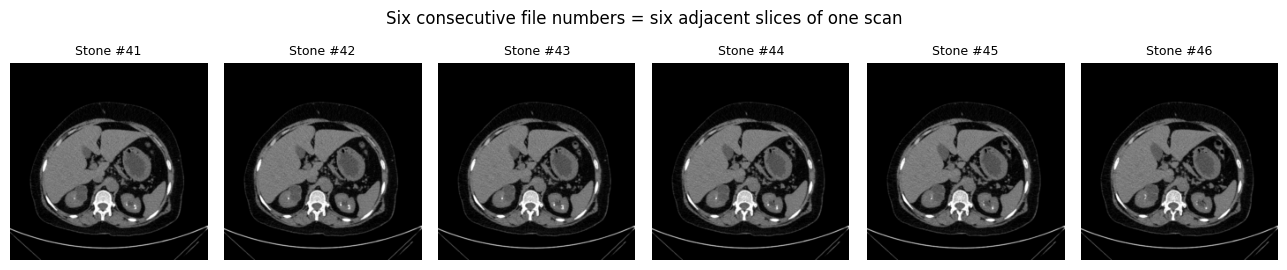

In [5]:
with torch.no_grad():
    feat = torch.cat([F.avg_pool2d(torch.from_numpy(X[i:i + 2048]).float()[:, None], 7).flatten(1)
                      for i in range(0, len(X), 2048)])
    feat = feat - feat.mean(1, keepdim=True)
    feat = feat / feat.norm(dim=1, keepdim=True)          # (N, 1024) unit vectors

# order every class by its file number and compare each slice with the next one
order = df.sort_values(["y", "num"]).index.values
f_ord = feat[order]
consec = (f_ord[:-1] * f_ord[1:]).sum(1).numpy()
same_class = df.y.values[order][:-1] == df.y.values[order][1:]
print("correlation between file k and file k+1 (same class):")
print(pd.Series(consec[same_class]).describe(percentiles=[.05, .25, .5]).round(4).to_string())

# show six consecutive files
start = df[(df.label == "Stone")].sort_values("num").index.values[40:46]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for a, i in zip(axes, start):
    a.imshow(X[i], cmap="gray"); a.axis("off"); a.set_title(f"Stone #{df.num[i]}", fontsize=9)
plt.suptitle("Six consecutive file numbers = six adjacent slices of one scan", y=1.02)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig_consecutive.png", dpi=150, bbox_inches="tight"); plt.show()

In [6]:
# Memorisation test: leave-one-out 1-nearest-neighbour on the 32x32 pixels. No training at all.
S = feat @ feat.T
S.fill_diagonal_(-1)
nn_sim, nn_idx = S.max(1)
loo_acc = (df.y.values[nn_idx.numpy()] == df.y.values).mean()
print(f"Leave-one-out 1-NN accuracy on raw 32x32 pixels: {100 * loo_acc:.2f} %")
print(f"Images whose nearest neighbour has correlation > 0.99: {100 * (nn_sim > 0.99).float().mean():.2f} %")
del S

Leave-one-out 1-NN accuracy on raw 32x32 pixels: 99.99 %
Images whose nearest neighbour has correlation > 0.99: 99.96 %


**What this shows.** Neighbouring file numbers are neighbouring slices of the same scan: the median correlation between file *k* and *k+1* is 0.999. Copying the label of the most similar other image, with no learning at all, gets **99.99 %** right, and 99.96 % of images have a near-twin (r > 0.99). So any split that scatters slices of one scan over train and test lets a model "recognise the patient" instead of the disease. This is the leakage named in the problem statement.

### Rebuilding pseudo-patient studies

Because real patient IDs are missing, I reconstruct **pseudo-studies** in two steps:

1. **Runs.** Walk through each class in file-number order and start a new run whenever the correlation to the previous file drops below 0.80 or the original image size changes (a different scan export).
2. **Merge.** Some scans are stored in two non-adjacent blocks. Two runs are merged (union-find) if any slice of one has correlation > 0.98 with any slice of the other.

Every slice of a pseudo-study must then go to the same split.

215 runs  ->  195 pseudo-studies after merging; studies containing >1 class: 0


,studies,median_slices,min_slices,max_slices
label,,,,
Normal,48,107.5,39,189
Cyst,66,29.5,6,300
Stone,58,15.5,2,173
Tumor,23,103.0,1,222


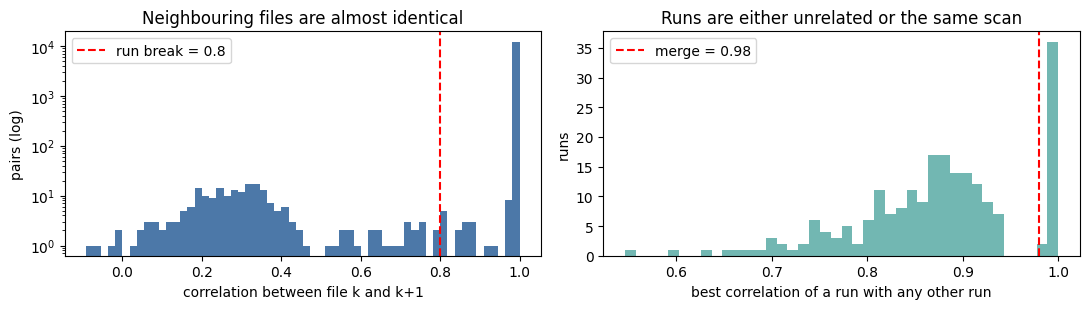

In [7]:
RUN_TH, MERGE_TH = 0.80, 0.98
w_ord, y_ord = df.w.values[order], df.y.values[order]
brk = (consec < RUN_TH) | (w_ord[:-1] != w_ord[1:]) | (y_ord[:-1] != y_ord[1:])
run = np.r_[0, np.cumsum(brk)]                        # run id for every slice (in sorted order)
R = run.max() + 1

# largest slice-to-slice correlation between every pair of runs
run_t = torch.from_numpy(run)
S_ord = f_ord @ f_ord.T
M = torch.zeros(R, R)
for r in range(R):
    best = S_ord[run_t == r].max(0).values
    M[r] = torch.stack([best[run_t == q].max() for q in range(R)])
M.fill_diagonal_(0)
del S_ord

parent = list(range(R))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for i, j in zip(*np.nonzero((M > MERGE_TH).numpy())):
    parent[find(i)] = find(j)
group_of_run = np.array([find(r) for r in range(R)])

df["group"] = -1
df.loc[order, "group"] = pd.factorize(group_of_run[run])[0]

g = df.groupby("group").agg(label=("label", "first"), n_classes=("y", "nunique"), slices=("y", "size"))
print(f"{R} runs  ->  {len(g)} pseudo-studies after merging; studies containing >1 class: {(g.n_classes > 1).sum()}")
display(g.groupby("label").slices.agg(studies="count", median_slices="median", min_slices="min", max_slices="max").reindex(CLASSES))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(consec[same_class], bins=60, color="#4c78a8"); ax[0].axvline(RUN_TH, color="r", ls="--", label=f"run break = {RUN_TH}")
ax[0].set_yscale("log"); ax[0].set_xlabel("correlation between file k and k+1"); ax[0].set_ylabel("pairs (log)"); ax[0].legend()
ax[0].set_title("Neighbouring files are almost identical")
ax[1].hist(M.max(1).values.numpy(), bins=40, color="#72b7b2"); ax[1].axvline(MERGE_TH, color="r", ls="--", label=f"merge = {MERGE_TH}")
ax[1].set_xlabel("best correlation of a run with any other run"); ax[1].set_ylabel("runs"); ax[1].legend()
ax[1].set_title("Runs are either unrelated or the same scan")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig_groups.png", dpi=150); plt.show()

**Result.** 215 runs merge into **195 pseudo-studies**, and none of them mixes two classes (a good sign that each one is one patient's scan). Stone has many short studies (median 15.5 slices) and Tumour has only **23 studies**. This matters later: the test set can hold only a handful of tumour patients.

*Limitation:* these are reconstructed groups, not real patient IDs. Two scans of the same patient taken on different days could still land in different groups.

## 4. Train / validation / test splits (Part C 5b)

Two splits are made with the **same seed (42)** and the same 70 / 15 / 15 target:

* **Random split** — stratified by class, slices shuffled individually. This is what most public notebooks on this dataset do.
* **Grouped split** — whole pseudo-studies are assigned to one split, class by class, so the class mix stays similar. *This is the split rule required by the problem statement and the one all final numbers come from.*

Both are saved to `outputs/splits.csv` so the exact split can be reloaded.

In [8]:
def random_split(df, seed):
    tr, tmp = train_test_split(df.index.values, test_size=0.30, stratify=df.y, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, stratify=df.y[tmp], random_state=seed)
    s = pd.Series("train", index=df.index); s[va] = "val"; s[te] = "test"
    return s

def grouped_split(df, seed, fracs={"train": 0.70, "val": 0.15, "test": 0.15}):
    # per class: shuffle the studies, give each one to the split that is furthest below its target size
    rng = np.random.default_rng(seed)
    s = pd.Series("train", index=df.index)
    for c in range(len(CLASSES)):
        sub = df[df.y == c]
        size = sub.groupby("group").size()
        have = {k: 0 for k in fracs}
        for gid in rng.permutation(size.index.values):
            k = max(fracs, key=lambda k: (fracs[k] * len(sub) - have[k]) / (fracs[k] * len(sub)))
            have[k] += size[gid]
            s[sub.index[sub.group == gid]] = k
    return s

df["split_random"]  = random_split(df, SEED)
df["split_grouped"] = grouped_split(df, SEED)
df[["path", "label", "y", "num", "group", "split_random", "split_grouped"]].to_csv(OUT_DIR / "splits.csv", index=False)

for col in ["split_random", "split_grouped"]:
    t = pd.crosstab(df[col], df.label).reindex(index=["train", "val", "test"], columns=CLASSES)
    t["total"] = t.sum(1)
    t["studies"] = [df[df[col] == k].group.nunique() for k in t.index]
    print(col); display(t)

# safety check: with the grouped split no study may appear in two splits
assert df.groupby("group").split_grouped.nunique().max() == 1
print("studies shared between splits  | random:", int((df.groupby("group").split_random.nunique() > 1).sum()),
      "| grouped:", int((df.groupby("group").split_grouped.nunique() > 1).sum()))

split_random


label,Normal,Cyst,Stone,Tumor,total,studies
split_random,,,,,,
train,3554,2596,964,1598,8712,194
val,761,557,206,343,1867,179
test,762,556,207,342,1867,186


split_grouped


label,Normal,Cyst,Stone,Tumor,total,studies
split_grouped,,,,,,
train,3531,2498,950,1549,8528,133
val,748,559,205,419,1931,30
test,798,652,222,315,1987,32


studies shared between splits  | random: 190 | grouped: 0


### Leakage audit of both splits

For every **test** slice I look up its most similar **training** slice. If the correlation is above 0.99 the test slice has a near-duplicate in the training set. I also run the no-learning 1-NN "classifier" from training set to test set.

,random split,grouped split
test slices with a near-duplicate in train (%),99.04,0.00
median best correlation to train,1.00,0.83
1-NN pixel accuracy on test (%),99.95,40.92
1-NN pixel Stone recall (%),100.00,40.09


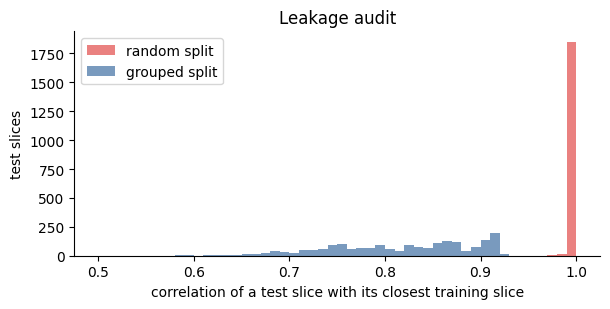

In [9]:
def audit(col):
    tr, te = df.index[df[col] == "train"].values, df.index[df[col] == "test"].values
    sim, idx = (feat[te] @ feat[tr].T).max(1)
    acc = (df.y.values[tr][idx.numpy()] == df.y.values[te]).mean()
    stone = df.y.values[te] == STONE
    rec = (df.y.values[tr][idx.numpy()][stone] == STONE).mean()
    return sim.numpy(), {"test slices with a near-duplicate in train (%)": 100 * (sim > 0.99).float().mean().item(),
                         "median best correlation to train": sim.median().item(),
                         "1-NN pixel accuracy on test (%)": 100 * acc,
                         "1-NN pixel Stone recall (%)": 100 * rec}

sim_r, a_r = audit("split_random"); sim_g, a_g = audit("split_grouped")
leak_table = pd.DataFrame({"random split": a_r, "grouped split": a_g}).round(2)
display(leak_table)

fig, ax = plt.subplots(figsize=(6.2, 3.2))
bins = np.linspace(0.5, 1, 51)
ax.hist(np.clip(sim_r, 0.5, 1), bins=bins, alpha=.75, label="random split", color="#e45756")
ax.hist(np.clip(sim_g, 0.5, 1), bins=bins, alpha=.75, label="grouped split", color="#4c78a8")
ax.set_xlabel("correlation of a test slice with its closest training slice"); ax.set_ylabel("test slices")
ax.set_title("Leakage audit"); ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig_leak_audit.png", dpi=200); plt.show()

**Leakage audit result.** With the **random split, 99.04 %** of test slices have a near-copy in training, and the no-learning 1-NN reaches **99.95 %** test accuracy (and 100 % Stone recall). With the **grouped split** this drops to **0.00 %** near-copies and **40.92 %** 1-NN accuracy. The grouped split therefore tests generalisation to new patients, while the random split mostly tests memory. The ~99 % accuracies often reported for this dataset come from random splits.

## 5. Model, pre-processing and augmentation (Part C 5c, 5d)

**Architecture.** ResNet-18 pretrained on ImageNet, with the final layer replaced by a 4-way classifier and **all layers fine-tuned**. Reasons:

* only ~130 independent training studies exist, so a from-scratch network would over-fit; pretrained edge/texture filters transfer well to CT;
* ResNet-18 (11.2 M parameters) is the smallest standard ResNet — enough capacity for 4 classes, trains in minutes on a laptop;
* 224 × 224 is the resolution the pretrained weights expect and still shows cysts, tumours and most stones.

**Pre-processing.** resize to 224 × 224 → scale to [0, 1] → copy the grey channel to 3 channels → ImageNet mean/std normalisation.

**Augmentation (training only, never on validation/test).** random rotation ±10°, zoom 0.9–1.1, shift ±5 %, horizontal flip, brightness ±0.1 and contrast 0.85–1.15. These mimic patient positioning and CT window differences without destroying small stones. It is applied per image on the GPU.

**Imbalance.** class-weighted cross-entropy (weight ∝ 1 / class frequency in the training split), so a missed Stone costs more than a missed Normal.

**Training.** AdamW, one-cycle cosine learning-rate schedule, label smoothing 0.05, a short budget of 3 epochs with the best-validation-macro-F1 checkpoint kept (early stopping, patience 3, as a safeguard); the best-validation checkpoint is the one evaluated.

**Every 8th slice for training (compute budget).** One training step of ResNet-18 takes about 1.4 s per batch on the laptop GPU used, so full training of four models would take hours. Section 3 showed neighbouring slices correlate at 0.999, so the training set uses only slices whose file number is divisible by 8 (~1,070 slices, still drawn from almost every training study). Validation and test always use every slice. This is a deliberate trade-off: the model is under-trained, and longer training is the first item of future work.

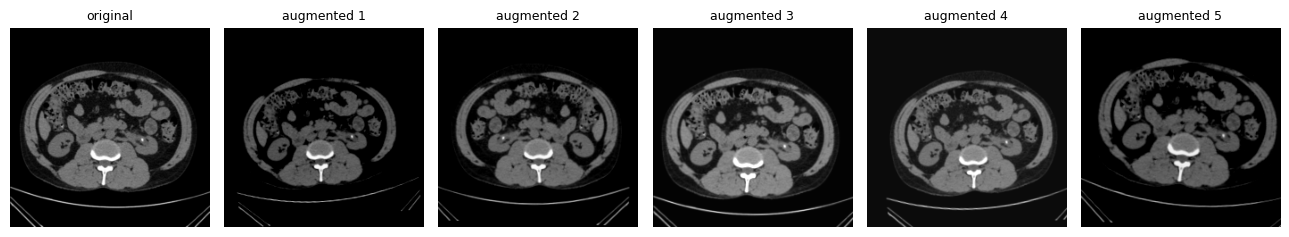

In [10]:
X_t = torch.from_numpy(X)                      # uint8, stays on the CPU; batches are moved to the device
y_t = torch.from_numpy(df.y.values)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def augment(x):
    # x: (B,1,H,W) in [0,1].  Independent random affine + intensity change for every image.
    B = x.size(0)
    ang   = (torch.rand(B, device=x.device) * 2 - 1) * np.deg2rad(10)
    scale = 1 + (torch.rand(B, device=x.device) * 2 - 1) * 0.10
    flip  = torch.where(torch.rand(B, device=x.device) < 0.5, -1.0, 1.0)
    shift = (torch.rand(B, 2, device=x.device) * 2 - 1) * 0.10          # grid units: 0.10 = 5 % of the width
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos * flip, -sin, shift[:, 0]], 1),
                         torch.stack([sin * flip,  cos, shift[:, 1]], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    contrast   = 1 + (torch.rand(B, 1, 1, 1, device=x.device) * 2 - 1) * 0.15
    brightness = (torch.rand(B, 1, 1, 1, device=x.device) * 2 - 1) * 0.10
    return ((x - 0.5) * contrast + 0.5 + brightness).clamp(0, 1)

def prep(idx, train=False):
    x = X_t[idx].to(device).float().div(255).unsqueeze(1)
    if train: x = augment(x)
    return (x.expand(-1, 3, -1, -1) - MEAN) / STD

def build_model(arch):
    if arch == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    elif arch == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, len(CLASSES))
    return m.to(device)

# what augmentation does to one image
set_seed(SEED)
i0 = int(df.index[df.label == "Stone"][100])
aug = augment(X_t[[i0] * 5].to(device).float().div(255).unsqueeze(1)).cpu()
fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
axes[0].imshow(X[i0], cmap="gray"); axes[0].set_title("original", fontsize=9)
for k in range(5): axes[k + 1].imshow(aug[k, 0], cmap="gray", vmin=0, vmax=1); axes[k + 1].set_title(f"augmented {k + 1}", fontsize=9)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

In [11]:
@torch.no_grad()
def predict(model, idx):
    model.eval()
    return torch.cat([F.softmax(model(prep(torch.as_tensor(idx[i:i + 256]))), 1).cpu()
                      for i in range(0, len(idx), 256)]).numpy()

def train_run(name, split_col, arch="resnet18", weighted=True, seed=SEED, epochs=EPOCHS):
    set_seed(seed)
    tr = df.index[df[split_col] == "train"].values
    va = df.index[df[split_col] == "val"].values
    # Adjacent slices are ~99.9 % identical (section 3), so sub-sampling every 8th slice keeps
    # (almost) every study and every part of each scan, at 1/8 of the cost. Validation/test use every slice.
    tr = tr[df.num.values[tr] % TRAIN_STRIDE == 0]
    model = build_model(arch)
    weight = None
    if weighted:
        freq = np.bincount(df.y.values[tr], minlength=len(CLASSES))
        weight = torch.tensor(len(tr) / (len(CLASSES) * freq), dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=weight, label_smoothing=0.05)
    val_loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    steps = int(np.ceil(len(tr) / BATCH))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=epochs * steps, pct_start=0.1)
    gen = torch.Generator().manual_seed(seed)
    hist, best, bad, t0 = [], {"f1": -1}, 0, time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl = tc = 0
        perm = torch.as_tensor(tr)[torch.randperm(len(tr), generator=gen)]
        for b in range(0, len(perm), BATCH):
            idx = perm[b:b + BATCH]
            yb = y_t[idx].to(device)
            out = model(prep(idx, train=True))
            loss = loss_fn(out, yb)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tl += loss.item() * len(idx); tc += (out.argmax(1) == yb).sum().item()
        pv = predict(model, va); yv = df.y.values[va]
        vl = val_loss_fn(torch.log(torch.from_numpy(pv) + 1e-9), torch.from_numpy(yv)).item()
        vf = f1_score(yv, pv.argmax(1), average="macro")
        hist.append({"epoch": ep, "train_loss": tl / len(tr), "train_acc": tc / len(tr), "val_loss": vl,
                     "val_acc": (pv.argmax(1) == yv).mean(), "val_macro_f1": vf,
                     "val_stone_recall": recall_score(yv, pv.argmax(1), labels=[STONE], average="macro")})
        print(f"[{name}] ep {ep:2d}  train loss {hist[-1]['train_loss']:.3f} acc {hist[-1]['train_acc']:.3f} | "
              f"val loss {vl:.3f} acc {hist[-1]['val_acc']:.3f} macroF1 {vf:.3f} stone-recall {hist[-1]['val_stone_recall']:.3f}")
        if vf > best["f1"]:
            best = {"f1": vf, "epoch": ep, "state": copy.deepcopy(model.state_dict())}; bad = 0
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"[{name}] early stop; best epoch = {best['epoch']}"); break
    model.load_state_dict(best["state"])
    torch.save(best["state"], OUT_DIR / f"model_{name}.pt")
    return {"name": name, "model": model, "hist": pd.DataFrame(hist), "best_epoch": best["epoch"],
            "minutes": (time.time() - t0) / 60, "split": split_col, "arch": arch, "weighted": weighted,
            "params_M": sum(p.numel() for p in model.parameters()) / 1e6}

runs = {}

### Run A — ResNet-18 on the **random** split (the leaky baseline)

In [12]:
runs["A_random"] = train_run("A_random", "split_random")

[A_random] ep  1  train loss 0.958 acc 0.613 | val loss 0.431 acc 0.864 macroF1 0.832 stone-recall 0.811


[A_random] ep  2  train loss 0.459 acc 0.919 | val loss 0.296 acc 0.904 macroF1 0.891 stone-recall 0.922


[A_random] ep  3  train loss 0.385 acc 0.953 | val loss 0.180 acc 0.953 macroF1 0.943 stone-recall 0.937


### Run B — the same ResNet-18, same settings, on the **grouped** split (main model)

In [13]:
runs["B_grouped"] = train_run("B_grouped", "split_grouped")

[B_grouped] ep  1  train loss 0.903 acc 0.663 | val loss 1.266 acc 0.442 macroF1 0.397 stone-recall 0.498


[B_grouped] ep  2  train loss 0.450 acc 0.919 | val loss 1.123 acc 0.502 macroF1 0.419 stone-recall 0.932


[B_grouped] ep  3  train loss 0.345 acc 0.969 | val loss 0.628 acc 0.697 macroF1 0.661 stone-recall 0.805


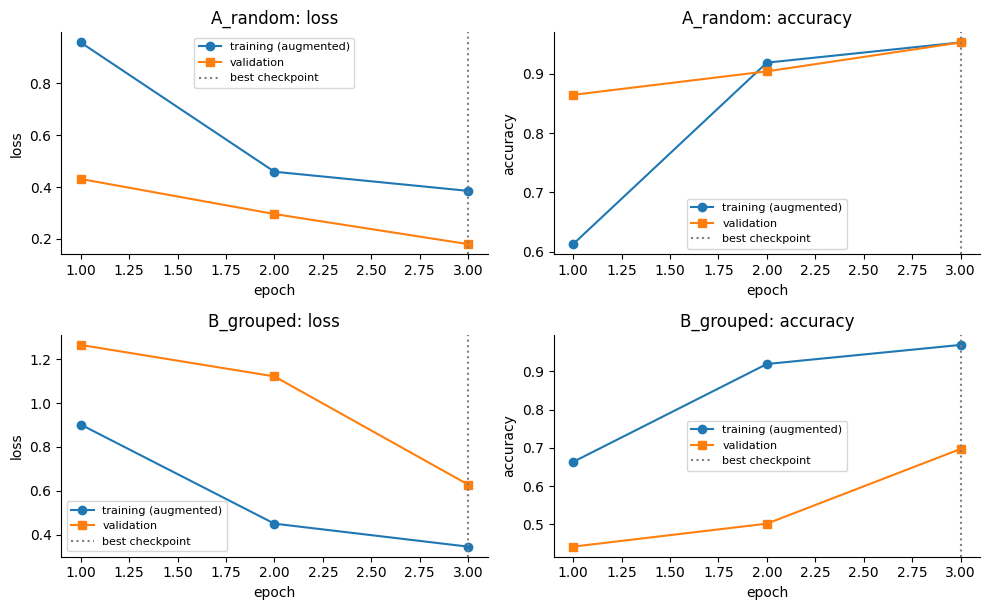

In [14]:
def plot_curves(keys, fname):
    fig, axes = plt.subplots(len(keys), 2, figsize=(10, 3.1 * len(keys)), squeeze=False)
    for r, k in enumerate(keys):
        h = runs[k]["hist"]
        for a, (m, lab) in zip(axes[r], [("loss", "loss"), ("acc", "accuracy")]):
            a.plot(h.epoch, h[f"train_{m}"], "o-", label="training (augmented)")
            a.plot(h.epoch, h[f"val_{m}"], "s-", label="validation")
            a.axvline(runs[k]["best_epoch"], color="grey", ls=":", label="best checkpoint")
            a.set_xlabel("epoch"); a.set_ylabel(lab); a.set_title(f"{k}: {lab}"); a.legend(fontsize=8)
            a.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=200); plt.show()

plot_curves(["A_random", "B_grouped"], "fig_curves.png")

**Reading the curves.**
* **Run A (random split):** training and validation accuracy rise together to ~95 %, and validation loss is *lower* than training loss. This looks like perfect generalisation, but it is an artefact: the validation slices are near-copies of training slices, so the leaky validation set **hides** over-fitting.
* **Run B (grouped split):** training accuracy reaches 96.9 % while validation accuracy is only 69.7 % at epoch 3. That 27-point gap is the real **generalisation gap to new patients**, i.e. over-fitting to the 133 training patients.
* In both runs validation loss is still falling at epoch 3, so the model is also **under-trained** (3-epoch budget on 1/8 of the slices). Longer training with the same regularisation (augmentation, weight decay, label smoothing, best-checkpoint selection) is the first improvement to try.

## 6. Evaluation on the test set (Part C 5e)

Each model is evaluated **once**, on the test part of the split it was trained with, using the best-validation checkpoint. Nothing was tuned on the test set.

Metrics and why:

* **Accuracy** — required, but misleading here because 41 % of the slices are Normal.
* **Per-class precision / recall / F1 and macro-F1** — macro-F1 gives every class equal weight, so the small Stone class counts as much as Normal. *Macro-F1 is my main metric.*
* **Stone recall** — named in the problem statement: of all true Stone slices, how many did the model find? A missed stone is a missed diagnosis.
* **Study-level accuracy** — majority vote over all slices of a pseudo-study, i.e. "was the patient's scan called correctly?".

In [15]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def evaluate(run):
    te = df.index[df[run["split"]] == "test"].values
    prob = predict(run["model"], te); pred = prob.argmax(1); y = df.y.values[te]
    rep = classification_report(y, pred, target_names=CLASSES, output_dict=True, zero_division=0)
    k, n = int(((pred == STONE) & (y == STONE)).sum()), int((y == STONE).sum())
    lo, hi = wilson(k, n)
    # study level: majority vote of the slices of each pseudo-study
    t = pd.DataFrame({"g": df.group.values[te], "y": y, "p": pred})
    study = t.groupby("g").agg(y=("y", "first"), p=("p", lambda s: s.value_counts().idxmax()))
    run.update(te=te, prob=prob, pred=pred, y=y, cm=confusion_matrix(y, pred, labels=range(len(CLASSES))), rep=rep)
    return {"model": run["arch"], "split": run["split"].replace("split_", ""), "class weights": run["weighted"],
            "test acc %": 100 * accuracy_score(y, pred), "macro-F1 %": 100 * rep["macro avg"]["f1-score"],
            "Stone recall %": 100 * k / n, "Stone recall 95% CI": f"{100 * lo:.1f}-{100 * hi:.1f}",
            "Stone precision %": 100 * rep["Stone"]["precision"],
            "Normal recall %": 100 * rep["Normal"]["recall"], "Cyst recall %": 100 * rep["Cyst"]["recall"],
            "Tumor recall %": 100 * rep["Tumor"]["recall"],
            "study-level acc %": 100 * (study.y == study.p).mean(), "test studies": len(study),
            "test slices": len(te), "best epoch": run["best_epoch"], "train min": run["minutes"], "params (M)": run["params_M"]}

results = {k: evaluate(runs[k]) for k in ["A_random", "B_grouped"]}
display(pd.DataFrame(results).T.round(2))

for k in ["A_random", "B_grouped"]:
    print(f"\n===== {k}: per-class report on its TEST set =====")
    print(classification_report(runs[k]["y"], runs[k]["pred"], target_names=CLASSES, digits=4, zero_division=0))
    print(f">>> Stone recall (test) = {results[k]['Stone recall %']:.2f} %   (95% CI {results[k]['Stone recall 95% CI']})")

,model,split,class weights,test acc %,macro-F1 %,Stone recall %,Stone recall 95% CI,Stone precision %,Normal recall %,Cyst recall %,Tumor recall %,study-level acc %,test studies,test slices,best epoch,train min,params (M)
A_random,resnet18,random,True,95.072309,94.20314,96.135266,92.6-98.0,85.407725,94.225722,98.561151,90.643275,95.698925,186,1867,3,1.60797,11.178564
B_grouped,resnet18,grouped,True,80.271766,69.74473,95.045045,91.3-97.2,58.611111,89.473684,93.865031,18.412698,71.875,32,1987,3,1.623036,11.178564



===== A_random: per-class report on its TEST set =====
              precision    recall  f1-score   support

      Normal     0.9742    0.9423    0.9580       762
        Cyst     0.9448    0.9856    0.9648       556
       Stone     0.8541    0.9614    0.9045       207
       Tumor     0.9779    0.9064    0.9408       342

    accuracy                         0.9507      1867
   macro avg     0.9378    0.9489    0.9420      1867
weighted avg     0.9528    0.9507    0.9509      1867

>>> Stone recall (test) = 96.14 %   (95% CI 92.6-98.0)

===== B_grouped: per-class report on its TEST set =====
              precision    recall  f1-score   support

      Normal     0.8925    0.8947    0.8936       798
        Cyst     0.8021    0.9387    0.8650       652
       Stone     0.5861    0.9505    0.7251       222
       Tumor     0.9062    0.1841    0.3061       315

    accuracy                         0.8027      1987
   macro avg     0.7967    0.7420    0.6974      1987
weighted avg     

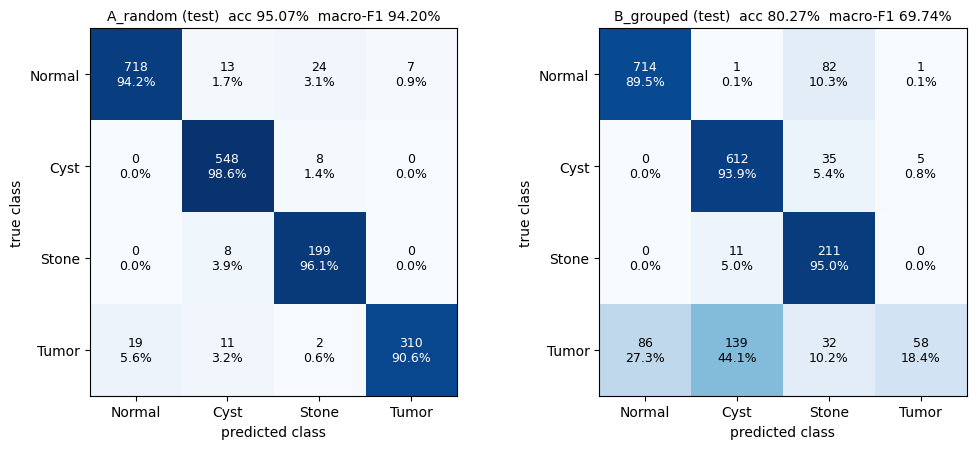

In [16]:
def plot_cms(keys, fname):
    fig, axes = plt.subplots(1, len(keys), figsize=(5.2 * len(keys), 4.6), squeeze=False)
    for a, k in zip(axes[0], keys):
        cm = runs[k]["cm"]; pct = cm / cm.sum(1, keepdims=True)
        a.imshow(pct, cmap="Blues", vmin=0, vmax=1)
        for i in range(4):
            for j in range(4):
                a.text(j, i, f"{cm[i, j]}\n{100 * pct[i, j]:.1f}%", ha="center", va="center", fontsize=9,
                       color="white" if pct[i, j] > 0.5 else "black")
        a.set_xticks(range(4)); a.set_xticklabels(CLASSES); a.set_yticks(range(4)); a.set_yticklabels(CLASSES)
        a.set_xlabel("predicted class"); a.set_ylabel("true class")
        a.set_title(f"{k} (test)  acc {results[k]['test acc %']:.2f}%  macro-F1 {results[k]['macro-F1 %']:.2f}%", fontsize=10)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=200); plt.show()

plot_cms(["A_random", "B_grouped"], "fig_cm.png")

**Key results (test sets).**

| Run | Split | Accuracy | Macro-F1 | Stone recall |
|---|---|---|---|---|
| A | random (leaky) | 95.07 % | 94.20 % | 96.14 % |
| **B** | **grouped (honest)** | **80.27 %** | **69.74 %** | **95.05 %** (95 % CI 91.3–97.2) |

* **Leakage inflates macro-F1 by 24.46 points** (94.20 → 69.74) with the same model and code. Only the split changed.
* **Stone recall stays high (95.05 %)** on unseen patients: 211 of 222 test stone slices were found. Stone precision is only 58.61 %, though: 149 non-stone slices were called Stone (82 Normal, 35 Cyst, 32 Tumour), so the model over-calls stones.
* **Tumour is the weak class:** recall is 18.41 %. Tumour slices go to Cyst (139) and Normal (86). The test set holds only 7 tumour studies, so this number depends heavily on those few patients.
* Accuracy (80.27 %) looks far better than macro-F1 (69.74 %), because Normal and Cyst are large, easy classes. That is why macro-F1 is the main metric.

## 7. Misclassified test images and Grad-CAM (Part C 5f)

Grad-CAM shows which image regions pushed the model towards a class: the gradient of the class score with respect to the last convolutional feature map (7 × 7 in ResNet-18) is averaged into channel weights, and the weighted feature maps are summed and up-sampled. Red = strong evidence for the predicted class.

Below are the eight **most confident wrong** predictions of the main model (Run B) on the grouped test set.

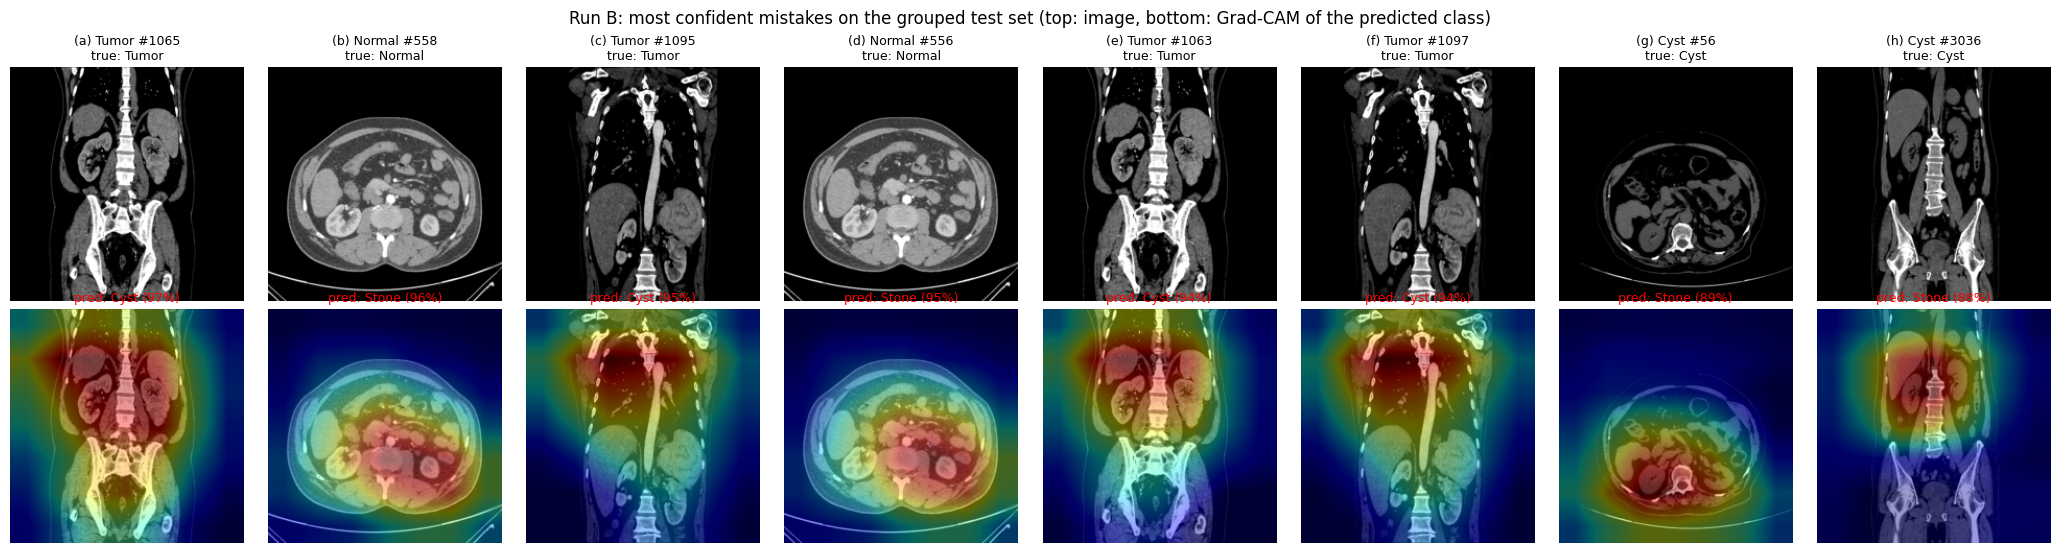

All test errors of Run B by (true -> predicted):


slices  studies
true   pred                   
Tumor  Cyst       139        3
       Normal      86        4
Normal Stone       82        2
Cyst   Stone       35        5
Tumor  Stone       32        2
Stone  Cyst        11        2
Cyst   Tumor        5        3
Normal Cyst         1        1
       Tumor        1        1

In [17]:
def gradcam(model, i, cls):
    model.eval(); store = {}
    layer = model.layer4 if hasattr(model, "layer4") else model.features[-1]
    def hook(m, inp, out):
        out.retain_grad(); store["a"] = out
    h = layer.register_forward_hook(hook)
    out = model(prep(torch.as_tensor([i])))
    model.zero_grad(); out[0, cls].backward(); h.remove()
    a, g = store["a"], store["a"].grad
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG, IMG), mode="bilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

def show_cases(run, idx_list, title, fname):
    n = len(idx_list)
    fig, axes = plt.subplots(2, n, figsize=(2.6 * n, 5.6), squeeze=False)
    pos = {int(i): k for k, i in enumerate(run["te"])}
    for c, i in enumerate(idx_list):
        k = pos[int(i)]; p = run["pred"][k]
        axes[0, c].imshow(X[i], cmap="gray")
        axes[0, c].set_title(f"({chr(97 + c)}) {df.label[i]} #{df.num[i]}\ntrue: {CLASSES[run['y'][k]]}", fontsize=9)
        axes[1, c].imshow(X[i], cmap="gray"); axes[1, c].imshow(gradcam(run["model"], int(i), int(p)), cmap="jet", alpha=0.4)
        axes[1, c].set_title(f"pred: {CLASSES[p]} ({100 * run['prob'][k, p]:.0f}%)", fontsize=9,
                             color="green" if p == run["y"][k] else "red")
        axes[0, c].axis("off"); axes[1, c].axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=170); plt.show()

B = runs["B_grouped"]
wrong = np.flatnonzero(B["pred"] != B["y"])
# most confident mistakes, but at most 2 per study so the examples are not 8 copies of one scan
wrong = wrong[np.argsort(-B["prob"][wrong].max(1))]
picked, per_study = [], {}
for k in wrong:
    gid = df.group.values[B["te"][k]]
    if per_study.get(gid, 0) < 2:
        picked.append(k); per_study[gid] = per_study.get(gid, 0) + 1
    if len(picked) == 8: break
mis_idx = B["te"][picked]
show_cases(B, mis_idx, "Run B: most confident mistakes on the grouped test set (top: image, bottom: Grad-CAM of the predicted class)", "fig_misclassified.png")

err = pd.DataFrame({"true": [CLASSES[t] for t in B["y"][wrong]], "pred": [CLASSES[p] for p in B["pred"][wrong]],
                    "group": df.group.values[B["te"][wrong]]})
print("All test errors of Run B by (true -> predicted):")
display(err.groupby(["true", "pred"]).agg(slices=("group", "size"), studies=("group", "nunique")).sort_values("slices", ascending=False))

**Why these slices were misclassified** (letters refer to the figure):

* **(a), (c), (e), (f) Tumour → Cyst (94–97 %).** These are coronal slices from two tumour studies. A renal tumour and a cyst are both round masses in the kidney. Telling them apart needs density (fluid vs. enhancing tissue), which is subtle at 224 px. Grad-CAM is spread over the upper abdomen and chest instead of the kidney mass, so the model did not find the lesion. Few tumour studies (23) and coronal views were rare in training.
* **(b), (d) Normal → Stone (95–96 %).** These are contrast-enhanced axial slices. Contrast in the renal pelvis, the aorta and the bones is very bright, like a stone. Grad-CAM sits on the spine/aorta region, so "bright spot near the kidney" is being read as a stone.
* **(g) Cyst → Stone (89 %).** A non-contrast slice. Grad-CAM points at the vertebra and the lower region rather than the cyst. Bone is the brightest structure, and the model partly uses it as a stone cue.
* **(h) Cyst → Stone (88 %).** A coronal slice where the heat-map covers the spine. Same bone-as-stone shortcut.

Several errors come in **pairs from the same study** (consecutive file numbers). Errors are correlated within a patient, which is why the study-level accuracy (71.88 %) is reported too.

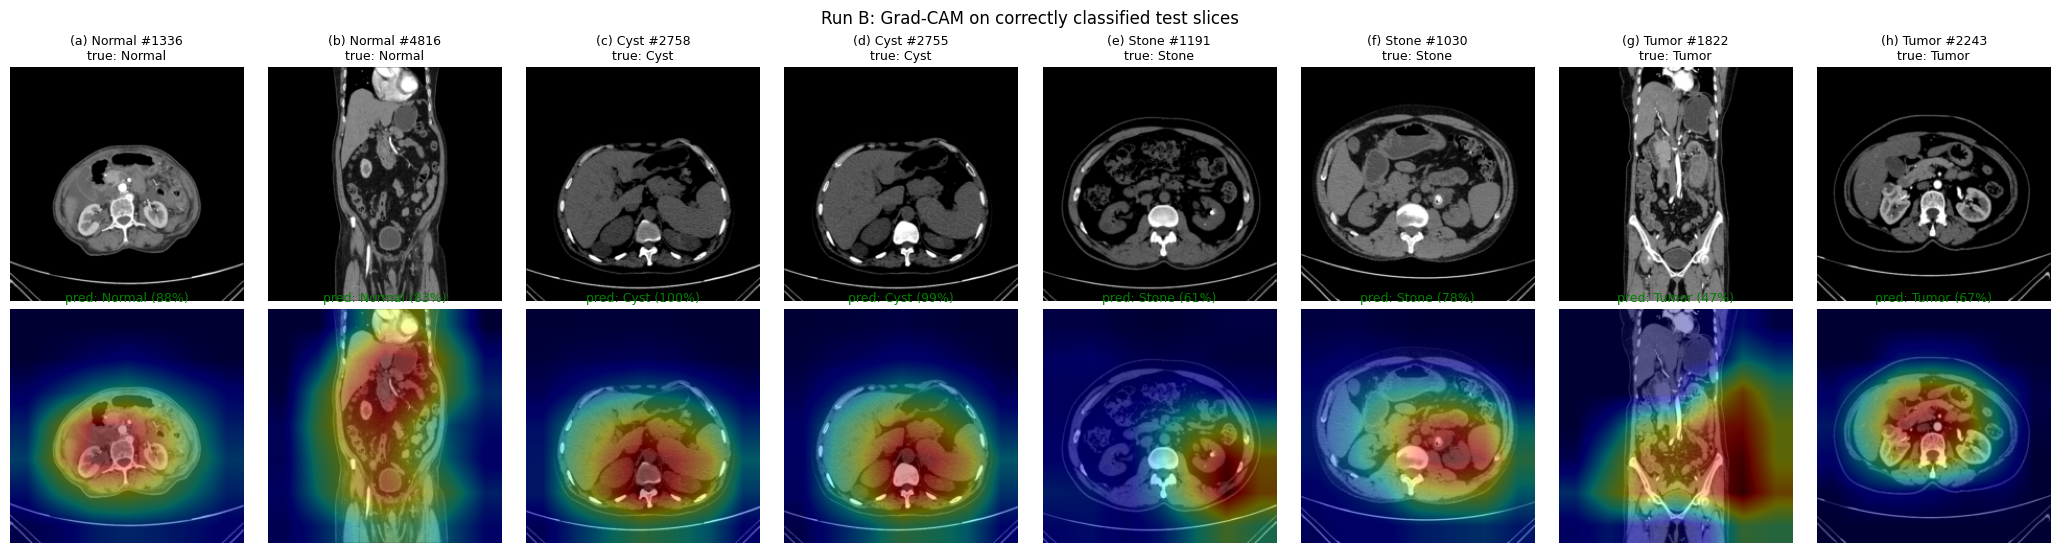

In [18]:
# Grad-CAM on correctly classified test slices: is the model looking at the kidneys?
ok = np.flatnonzero(B["pred"] == B["y"])
rng = np.random.default_rng(SEED)
good_idx = np.concatenate([B["te"][rng.choice(ok[B["y"][ok] == c], 2, replace=False)] for c in range(4)])
show_cases(B, good_idx, "Run B: Grad-CAM on correctly classified test slices", "fig_gradcam_correct.png")

**Grad-CAM on correct predictions.** For the stone slices (e, f) the heat is on the left kidney, where the bright stone is, which is good. For Normal and Cyst the heat covers the central abdomen, kidneys and spine broadly. For tumour (g) the strongest response lies partly **outside the body**, so that correct answer is not trustworthy. Together with the mistakes above, this suggests the model partly uses global cues (contrast phase, bone, view direction) rather than only the lesion. That is a known risk with this dataset and a reason not to trust slice-level accuracy alone.

## 8. Going beyond one baseline

Two extra experiments, both on the **grouped** split so that they are comparable with Run B:

* **Run C — no class weights.** Same as Run B but with plain cross-entropy. Does the weighting actually help Stone recall?
* **Run D — MobileNetV3-Small.** A 1.5 M-parameter network (7× smaller than ResNet-18). Does a lightweight model lose accuracy?

In [19]:
runs["C_grouped_noweights"] = train_run("C_grouped_noweights", "split_grouped", weighted=False)
runs["D_mobilenet"] = train_run("D_mobilenet", "split_grouped", arch="mobilenet_v3_small")
for k in ["C_grouped_noweights", "D_mobilenet"]:
    results[k] = evaluate(runs[k])

[C_grouped_noweights] ep  1  train loss 0.810 acc 0.685 | val loss 1.050 acc 0.590 macroF1 0.494 stone-recall 0.483


[C_grouped_noweights] ep  2  train loss 0.371 acc 0.945 | val loss 0.800 acc 0.632 macroF1 0.531 stone-recall 0.888


[C_grouped_noweights] ep  3  train loss 0.291 acc 0.981 | val loss 0.478 acc 0.793 macroF1 0.735 stone-recall 0.639


[D_mobilenet] ep  1  train loss 1.250 acc 0.481 | val loss 1.275 acc 0.365 macroF1 0.271 stone-recall 0.112


[D_mobilenet] ep  2  train loss 0.833 acc 0.779 | val loss 1.351 acc 0.355 macroF1 0.282 stone-recall 0.527


[D_mobilenet] ep  3  train loss 0.696 acc 0.810 | val loss 1.307 acc 0.398 macroF1 0.339 stone-recall 0.507


In [20]:
res = pd.DataFrame(results).T
display(res.round(2))

,model,split,class weights,test acc %,macro-F1 %,Stone recall %,Stone recall 95% CI,Stone precision %,Normal recall %,Cyst recall %,Tumor recall %,study-level acc %,test studies,test slices,best epoch,train min,params (M)
A_random,resnet18,random,True,95.072309,94.20314,96.135266,92.6-98.0,85.407725,94.225722,98.561151,90.643275,95.698925,186,1867,3,1.60797,11.178564
B_grouped,resnet18,grouped,True,80.271766,69.74473,95.045045,91.3-97.2,58.611111,89.473684,93.865031,18.412698,71.875,32,1987,3,1.623036,11.178564
C_grouped_noweights,resnet18,grouped,False,79.265224,65.91182,90.540541,86.0-93.7,67.449664,91.729323,95.245399,6.666667,68.75,32,1987,3,1.534444,11.178564
D_mobilenet,mobilenet_v3_small,grouped,True,44.237544,36.799766,68.018018,61.6-73.8,18.30303,8.145363,91.411043,21.269841,40.625,32,1987,3,0.396284,1.521956


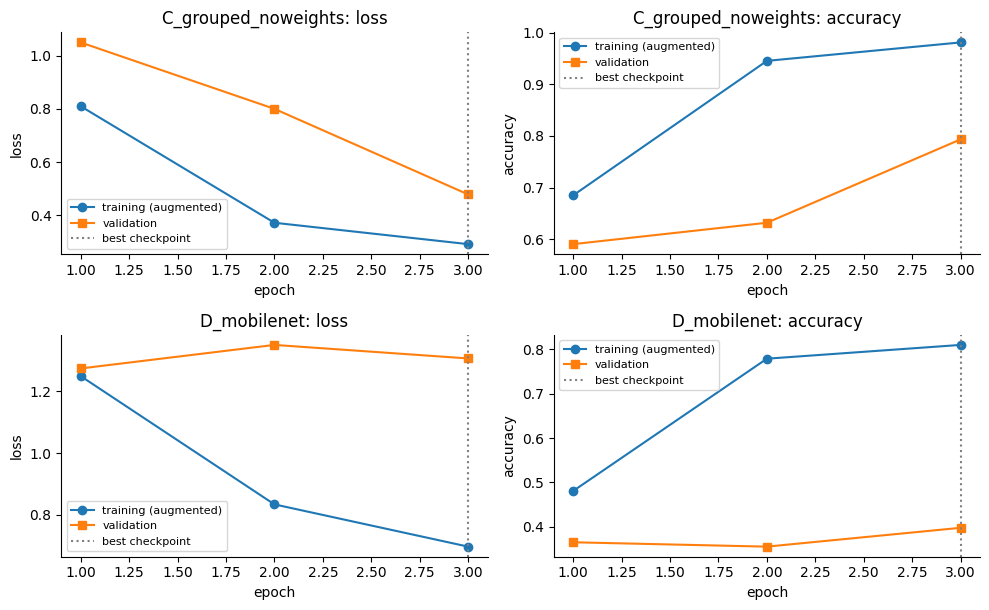

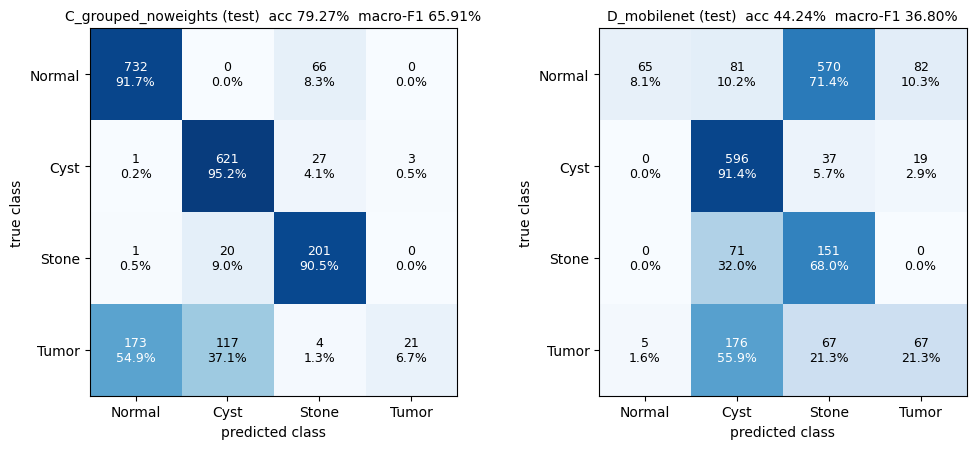

In [21]:
plot_curves(["C_grouped_noweights", "D_mobilenet"], "fig_curves_extra.png")
plot_cms(["C_grouped_noweights", "D_mobilenet"], "fig_cm_extra.png")

**What the extra experiments show** (all on the same grouped split as Run B):

| Run | Change | Macro-F1 | Stone recall | Tumour recall |
|---|---|---|---|---|
| B | class-weighted loss | 69.74 % | 95.05 % | 18.41 % |
| C | **no** class weights | 65.91 % | 90.54 % | 6.67 % |
| D | MobileNetV3-Small (1.5 M params) | 36.80 % | 68.02 % | 21.27 % |

* **Class weights help the small classes:** removing them lowers Stone recall by 4.50 points (95.05 → 90.54), Tumour recall by 11.75 points and macro-F1 by 3.83 points. They also lower Stone precision (67.45 → 58.61 %), which is the usual recall–precision trade-off.
* **The lightweight model did not converge in the 3-epoch budget.** Its training accuracy was only 81 %, and it labels most Normal slices as Stone (Normal recall 8.15 %). It is 7× smaller and trains in 0.40 min instead of 1.62 min. With this budget, though, ResNet-18 is clearly the better choice. A fair comparison would need longer training.

## 9. Save everything needed to reproduce the reported numbers

In [22]:
summary_out = {
    "seed": SEED, "device": str(device),
    "versions": {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
    "config": {"img": IMG, "batch": BATCH, "max_epochs": EPOCHS, "patience": PATIENCE, "lr": LR, "weight_decay": WD,
               "run_threshold": RUN_TH, "merge_threshold": MERGE_TH},
    "n_images": len(df), "n_pseudo_studies": int(df.group.nunique()), "loo_1nn_pixel_acc": float(loo_acc),
    "leak_audit": leak_table.to_dict(), "results": results,
    "confusion": {k: runs[k]["cm"].tolist() for k in runs},
    "history": {k: runs[k]["hist"].to_dict("list") for k in runs},
    "misclassified_shown": [{"path": df.path[i], "group": int(df.group[i])} for i in mis_idx],
}
json.dump(summary_out, open(OUT_DIR / "results.json", "w"), indent=1, default=float)
res.to_csv(OUT_DIR / "results_table.csv")
print("saved:", sorted(p.name for p in OUT_DIR.iterdir()))

saved: ['fig_class_counts.png', 'fig_cm.png', 'fig_cm_extra.png', 'fig_consecutive.png', 'fig_curves.png', 'fig_curves_extra.png', 'fig_gradcam_correct.png', 'fig_groups.png', 'fig_leak_audit.png', 'fig_misclassified.png', 'fig_samples.png', 'model_A_random.pt', 'model_B_grouped.pt', 'model_C_grouped_noweights.pt', 'model_D_mobilenet.pt', 'results.json', 'results_table.csv', 'splits.csv']


## 10. Summary

* **Challenge (data leakage):** neighbouring slices are near-identical. The rebuilt pseudo-patient grouping removes all near-duplicates between train and test (99.04 % → 0.00 %), and the same ResNet-18 drops from 94.20 % to **69.74 % macro-F1**. The honest number is the second one.
* **Stone (smallest class), reported separately:** **95.05 % recall** (95 % CI 91.3–97.2) on unseen patients, helped by class-weighted loss (+4.50 points vs. no weights). Precision is only 58.61 %, so stones are over-called.
* **Weakness:** Tumour recall is 18.41 % (confused with Cyst/Normal), from only 7 test studies.
* **Limitation:** short training budget (3 epochs, 1/8 of the training slices) because of laptop compute. Validation loss was still falling.

**Reproducibility:** seed 42 everywhere (section 1); library versions printed in section 1; the exact split saved in `outputs/splits.csv`; all numbers in `outputs/results.json`; model weights in `outputs/model_*.pt`. Running all cells top to bottom recreates every number.